# Check correlation between Delta Z and Delta V
We want to check if the velocities output by MultiVelo are somehow connected to motif accessibility, represented by ChromVAR z-scores. We compare pairs of cells that close within the RNA embedding but have vastly different accessibility scores and compute differences in velocity. Ultimately we can compute a correlation between the Delta 

In [67]:
import scanpy as sc
import numpy as np 
import matplotlib.pyplot as plt
import multivelo as mv
import pandas as pd
import scvelo as scv
from pathlib import Path
from scipy.spatial.distance import cdist, euclidean
from scipy.optimize import linear_sum_assignment
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from matplotlib.collections import LineCollection
from sklearn.neighbors import NearestNeighbors
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from matplotlib.lines import Line2D

python_data_dir = r"C:\Users\Nikla\Documents\MoBi_Master_FS.3\Internship AG Höfer\DynaVelo_testing\data"

scv.settings.verbosity = 3
scv.settings.presenter_view = True
scv.set_figure_params('scvelo')
scv.settings.figdir = rf"{python_data_dir}\multivelo_comparison"
scv.settings.plot_prefix = ""
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 200)
np.set_printoptions(suppress=True)

In [2]:
mv_data = sc.read_h5ad(rf"{python_data_dir}\multivelo_results_v2.h5ad")
adata_atac = sc.read_h5ad(fr"{python_data_dir}\all_atac_aggregated_peaks.h5ad")

In [3]:
adata_atac = adata_atac[mv_data.obs_names, mv_data.var_names]
nn_idx = np.loadtxt(rf"{python_data_dir}/nn_idx.txt", delimiter=',')
nn_dist = np.loadtxt(rf"{python_data_dir}/nn_dist.txt", delimiter=',')
mv.knn_smooth_chrom(adata_atac, nn_idx, nn_dist)

In [4]:
z_scores = sc.read_h5ad(rf"{python_data_dir}\z_scores_raw.h5ad")
z_scores.obs_names = [i[9:-2] for i in z_scores.obs_names.values]
intersect_cells = np.intersect1d(adata_atac.obs_names, z_scores.obs_names)

adata_atac = adata_atac[intersect_cells,:]
z_scores = z_scores[intersect_cells,:]
mv_data = mv_data[intersect_cells,:]

In [5]:
mv.velocity_graph(mv_data)
mv.latent_time(mv_data)

computing velocity graph (using 1/8 cores)


  0%|          | 0/5241 [00:00<?, ?cells/s]

    finished (0:00:09) --> added 
    'velo_s_norm_graph', sparse matrix with cosine correlations (adata.uns)
computing terminal states
    identified 0 region of root cells and 2 regions of end points .
    finished (0:00:00) --> added
    'root_cells', root cells of Markov diffusion process (adata.obs)
    'end_points', end points of Markov diffusion process (adata.obs)
computing latent time using root_cells as prior
    finished (0:00:01) --> added 
    'latent_time', shared time (adata.obs)


computing velocity embedding
    finished (0:00:02) --> added
    'velo_s_norm_umap', embedded velocity vectors (adata.obsm)


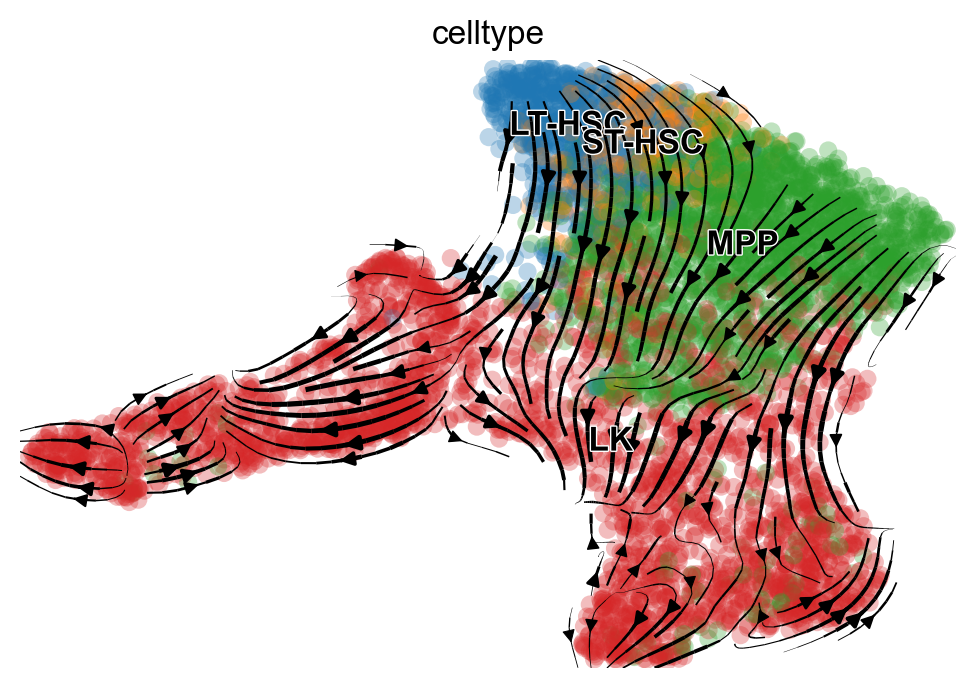

computing velocity embedding
    finished (0:00:02) --> added
    'velo_s_norm_pca', embedded velocity vectors (adata.obsm)


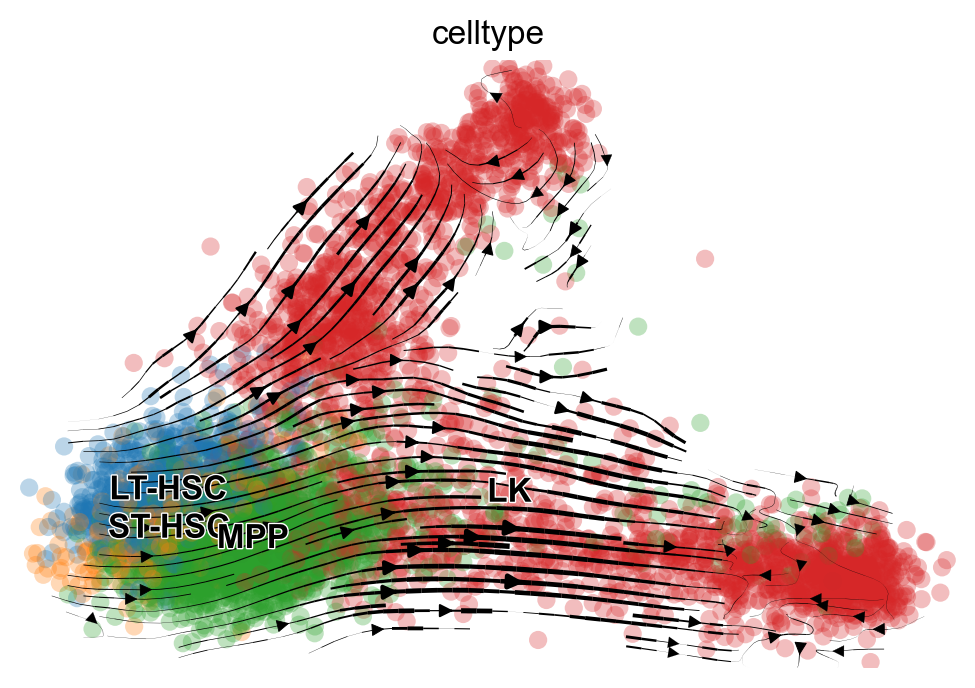

In [6]:
mv.velocity_embedding_stream(mv_data, basis='umap', color='celltype')
mv.velocity_embedding_stream(mv_data, basis="pca", vkey="velo_s", color="celltype")

## Define TFs, data and Functions

In [7]:
tfs = ["HOXA9", "SPI1", "CEBPA", "GATA1", "GATA2", "MYC"]

for i, tf in enumerate(tfs): 

    tf_data = z_scores[:, tf].X.flatten()

    labels = pd.qcut(
        tf_data,
        q=[0, 0.25, 0.75, 1.0],  
        labels=["low", "med", "high"],
    )

    mv_data.obs[f"{tf}_zscore"] = pd.Series(labels, index=z_scores.obs_names).reindex(mv_data.obs_names)

In [8]:
mv_data

AnnData object with n_obs × n_vars = 5241 × 310
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'Sample', 'TSSEnrichment', 'ReadsInTSS', 'ReadsInPromoter', 'ReadsInBlacklist', 'PromoterRatio', 'PassQC', 'NucleosomeRatio', 'nMultiFrags', 'nMonoFrags', 'nFrags', 'nDiFrags', 'BlacklistRatio', 'percent.mt', 'nCount_SCT', 'nFeature_SCT', 'S.Score', 'G2M.Score', 'Phase', 'SCT_snn_res.0.8', 'seurat_clusters', 'doublets_normal_cluster_based', 'doublets_random', 'doublets_RNA_consensus', 'nCount_SCT_no_regression', 'nFeature_SCT_no_regression', 'tricyclePosition', 'Phase_tricycle', 'tricycle_fine', 'cell_cycle_atac_classification', 'PromoterPercent', 'immunophenotype_predicted', 'predicted.id', 'prediction.score.LT', 'prediction.score.ST', 'prediction.score.MPP', 'prediction.score.LS_K', 'prediction.score.max', 'Identity_for_diff_testing', 'RF_prediction', 'angle_degree', 'immunophenotype_predicted_cleaned', 'HSC.promoters', 'LMPP.promoters', 'myeloid.promoters', 'MEP.promoters', 'HSC.TSS'

In [8]:
X_pca = mv_data.obsm["X_pca"]
n_pcs = X_pca.shape[1]          # or slice to e.g. X_pca[:, :30] if you only want the top N
pca_cols = [f"PC{i+1}" for i in range(n_pcs)]

umap_velos = mv_data.obsm["velo_s_norm_umap"]
velo_df = pd.DataFrame(umap_velos, index=mv_data.obs_names.values)
velo_df.rename(columns={0: "vx", 1: "vy"}, inplace=True)
velo_df.index.rename("cell", inplace=True)
velo_df["celltype"] = mv_data.obs["celltype"]
velo_df[["x", "y"]] = mv_data.obsm["X_umap"]      # keep if you still want UMAP for plotting
velo_df[pca_cols] = X_pca                         # new: PCA coords for neighbor search

for tf in tfs:
    velo_df[tf] = mv_data.obs[f"{tf}_zscore"]

velo_df = velo_df.loc[velo_df["celltype"] != "LK", :]

In [9]:
vpca_velos = mv_data.obsm["velo_s_norm_pca"]
vpca = pd.DataFrame(vpca_velos, index=mv_data.obs_names.values)

In [66]:
def vec_diff(v1, v2):
    diff = np.linalg.norm(v1, axis=-1)-np.linalg.norm(v2, axis=-1)  # This is signed!
    return diff

def unit_vector(vector):
    """ Returns the unit vector of the vector.  """
    return vector / np.linalg.norm(vector)

def angle_between(v1, v2):
    """ Returns the angle in radians between vectors 'v1' and 'v2'::

            >>> angle_between((1, 0, 0), (0, 1, 0))
            1.5707963267948966
            >>> angle_between((1, 0, 0), (1, 0, 0))
            0.0
            >>> angle_between((1, 0, 0), (-1, 0, 0))
            3.141592653589793
    """
    v1_u = unit_vector(v1)
    v2_u = unit_vector(v2)
    return np.arccos(np.clip(np.dot(v1_u, v2_u), -1.0, 1.0))

def _first_non_nan(matrix):
    """
    Row-wise first non-NaN value. Columns are assumed already ordered by
    distance (nearest first), so this picks the nearest still-valid
    candidate for each row. Translates the R idiom:
        apply(x, 1, function(x) x[which(!is.na(x))[1]])
    """
    result = np.full(matrix.shape[0], np.nan)
    for i in range(matrix.shape[0]):
        row = matrix[i]
        valid = row[~np.isnan(row)]
        if valid.size:
            result[i] = valid[0]
    return result


def pair_cells_mnn(gene_atac, z_scores, velo_df, mv_data,
                    celltype="MPP", k=10, coord_cols=("x", "y")):
    """
    Iterative mutual-nearest-neighbor 1-to-1 pairing of 'high' vs 'low'
    z-score cells for a single gene, translated from an R implementation
    (match_cells()).

    Unlike a Hungarian-assignment pairing, this does NOT force every hi/lo
    cell into a pair. Each round: for every still-unmatched 'high' cell,
    find its nearest still-available 'low' neighbor; then check that THAT
    'low' cell's nearest still-available 'high' neighbor maps back to the
    same 'high' cell (i.e. they're mutual nearest neighbors). Only mutual
    pairs are locked in; the round repeats on whatever remains unmatched
    until a round locks in no new pairs. Cells that never find a mutual
    partner are dropped, so the result can cover far fewer than all hi/lo
    cells - that's expected, matching the R behavior.

    Returns a DataFrame with columns 'partner_hi', 'partner_lo'.
    """
    # 1. Quantile labels for this one gene (same as the Hungarian version)
    gene_data = z_scores[:, gene_atac].X.flatten()
    labels = pd.qcut(gene_data, q=[0, 0.25, 0.75, 1.0], labels=["low", "med", "high"])
    velo_df[gene_atac] = pd.Series(labels, index=z_scores.obs_names).reindex(mv_data.obs_names)

    cols = list(coord_cols)  # a tuple would be read as a single (multi-index) key, so convert to a list
    velo_df = velo_df[(velo_df[cols] <= 0).all(axis=1)]

    # 2. Restrict to the cell type of interest. 'med' cells are kept in the
    #    neighbor search space (like the R code's neighbor_obj spanning the
    #    whole object) so they can be skipped over as candidates, exactly as
    #    the R masking step drops any neighbor that isn't in group1/group2.
    #ct_mask = velo_df["celltype"] == celltype
    subset = velo_df.loc[:, list(coord_cols) + [gene_atac]].dropna(subset=[gene_atac])
    if subset.empty:
        return pd.DataFrame(columns=["partner_hi", "partner_lo"])

    subset = subset.reset_index()  # keep original obs index as a column; use 0..n-1 as positions
    obs_id_col = subset.columns[0]
    obs_ids = subset[obs_id_col].to_numpy()

    hi_pos = subset.index[subset[gene_atac] == "high"].to_numpy()
    lo_pos = subset.index[subset[gene_atac] == "low"].to_numpy()
    if hi_pos.size == 0 or lo_pos.size == 0:
        return pd.DataFrame(columns=["partner_hi", "partner_lo"])

    # 3. KNN index matrix over ALL cells in `subset` (hi + med + lo) - this
    #    mirrors the R code's neighbor_obj/search_space. Column 0 is each
    #    cell's own position (self, distance 0); columns 1:k+1 are its k
    #    nearest neighbors, closest first.
    coords = subset[list(coord_cols)].values
    n_neighbors = min(k + 1, len(subset))
    if n_neighbors < 2:
        return pd.DataFrame(columns=["partner_hi", "partner_lo"])
    nn = NearestNeighbors(n_neighbors=n_neighbors).fit(coords)
    _, nn_idx = nn.kneighbors(coords)

    # 4. Iterative mutual-nearest-neighbor matching, translated from the R
    #    match_cells() loop.
    hi_set = set(hi_pos.tolist())
    lo_set = set(lo_pos.tolist())
    allowed = hi_set | lo_set

    unmatched_hi = hi_pos.copy()
    unmatched_lo = lo_pos.copy()
    matched_pairs = []

    n_prev_unmatched = len(unmatched_hi) + 1
    n_curr_unmatched = len(unmatched_hi)

    while n_curr_unmatched < n_prev_unmatched:
        # -- nearest still-available 'low' neighbor for each unmatched 'high' cell --
        hi_neighbors = nn_idx[unmatched_hi, 1:].astype(float).copy()
        matched_lo = np.setdiff1d(lo_pos, unmatched_lo)
        invalid = (
            np.isin(hi_neighbors, list(hi_set))      # neighbor is itself a 'high' cell
            | np.isin(hi_neighbors, matched_lo)       # neighbor is an already-matched 'low' cell
            | ~np.isin(hi_neighbors, list(allowed))   # neighbor is in neither group
        )
        hi_neighbors[invalid] = np.nan
        nearest_lo = _first_non_nan(hi_neighbors)

        have_candidate = ~np.isnan(nearest_lo)
        hi_init = unmatched_hi[have_candidate]
        lo_candidate = nearest_lo[have_candidate].astype(int)

        # -- nearest still-available 'high' neighbor for each candidate 'low' cell --
        lo_neighbors = nn_idx[lo_candidate, 1:].astype(float).copy()
        matched_hi = np.setdiff1d(hi_pos, unmatched_hi)
        invalid_back = (
            np.isin(lo_neighbors, list(lo_set))
            | np.isin(lo_neighbors, matched_hi)
            | ~np.isin(lo_neighbors, list(allowed))
        )
        lo_neighbors[invalid_back] = np.nan
        hi_back = _first_non_nan(lo_neighbors)

        # a pair is only confirmed if it's reciprocal (NaN != anything, so
        # candidates with no valid back-neighbor are excluded automatically)
        is_mutual = hi_back == hi_init
        newly_matched_hi = hi_init[is_mutual]
        newly_matched_lo = lo_candidate[is_mutual]

        n_prev_unmatched = len(unmatched_hi)
        unmatched_hi = np.setdiff1d(unmatched_hi, newly_matched_hi)
        n_curr_unmatched = len(unmatched_hi)
        unmatched_lo = np.setdiff1d(unmatched_lo, newly_matched_lo)

        matched_pairs.append(pd.DataFrame({"hi_pos": newly_matched_hi, "lo_pos": newly_matched_lo}))

    if not matched_pairs:
        return pd.DataFrame(columns=["partner_hi", "partner_lo"])

    result = pd.concat(matched_pairs, ignore_index=True)
    return pd.DataFrame({
        "partner_hi": obs_ids[result["hi_pos"].to_numpy()],
        "partner_lo": obs_ids[result["lo_pos"].to_numpy()],
    })

## Validate Pairing Function
Simple check to see if the pairing is working as intended

In [40]:
pairing_df = pair_cells_mnn("MYC", z_scores, velo_df, mv_data, coord_cols=pca_cols[:2], k=10)

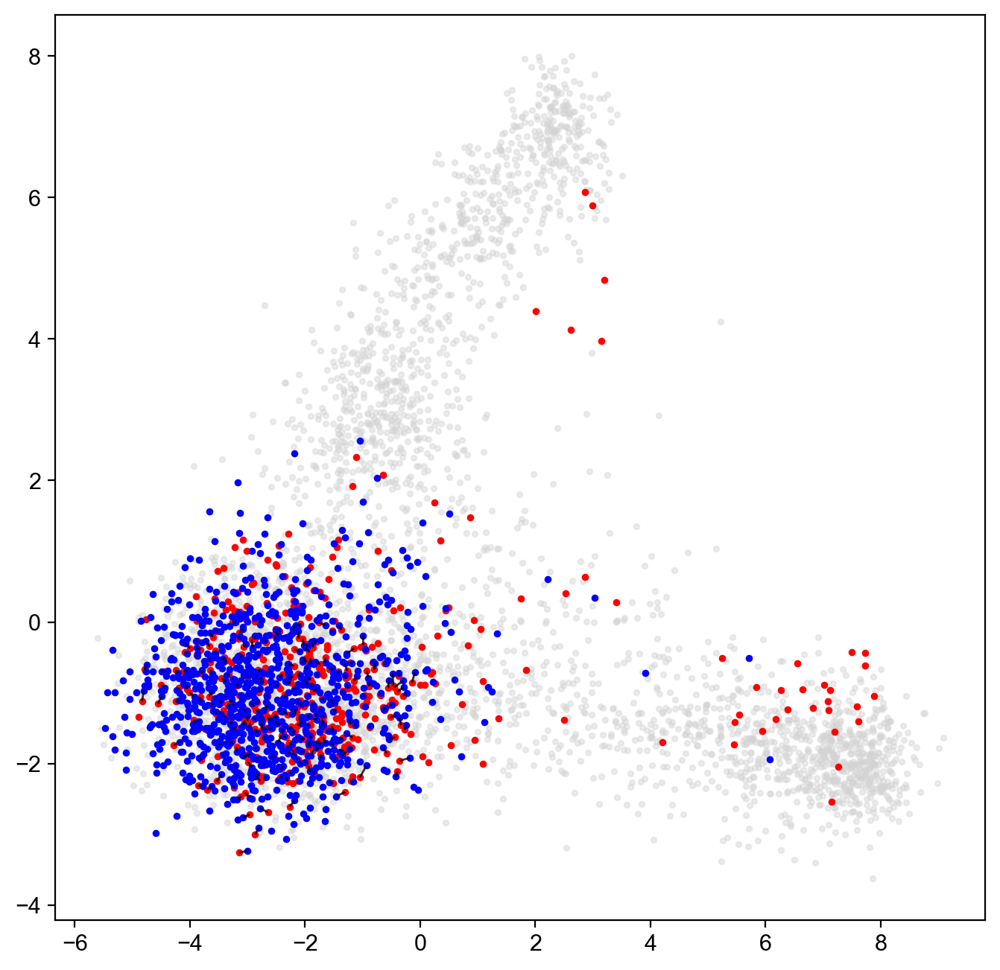

In [41]:
hi = velo_df.loc[velo_df["MYC"]=="high", :]
lo = velo_df.loc[velo_df["MYC"]=="low", :]

fig, ax = plt.subplots(figsize=(8,8))

# draw the connecting lines first so they sit behind the points
hi_xy = hi.loc[pairing_df["partner_hi"], ["PC1", "PC2"]].to_numpy()
lo_xy = lo.loc[pairing_df["partner_lo"], ["PC1", "PC2"]].to_numpy()
segments = np.stack([hi_xy, lo_xy], axis=1)  # shape (n_pairs, 2, 2)

lc = LineCollection(segments, colors="black", linewidths=1, alpha=0.8, zorder=3)
ax.add_collection(lc)

ax.scatter(mv_data.obsm["X_pca"][:,0], mv_data.obsm["X_pca"][:,1], c="lightgrey", zorder=0, s=6, alpha=0.4)
ax.scatter(hi["PC1"], hi["PC2"], c="red", s=6, zorder=2)
ax.scatter(lo["PC1"], lo["PC2"], c="blue", s=6, zorder=2)

plt.show()

There appears to be some sort of error, but the "problem" in the visualization is that this just shows the first two PCs, while all 30 are used to compute the neighbors and minimize the distances. We run a little test to see the effect that the parameter k has on the number of neighbors.

k= 10:    15 pairs  |  median dist = 0.054
k= 20:    20 pairs  |  median dist = 0.066
k= 30:    24 pairs  |  median dist = 0.085
k= 50:    27 pairs  |  median dist = 0.098
k=100:    32 pairs  |  median dist = 0.125


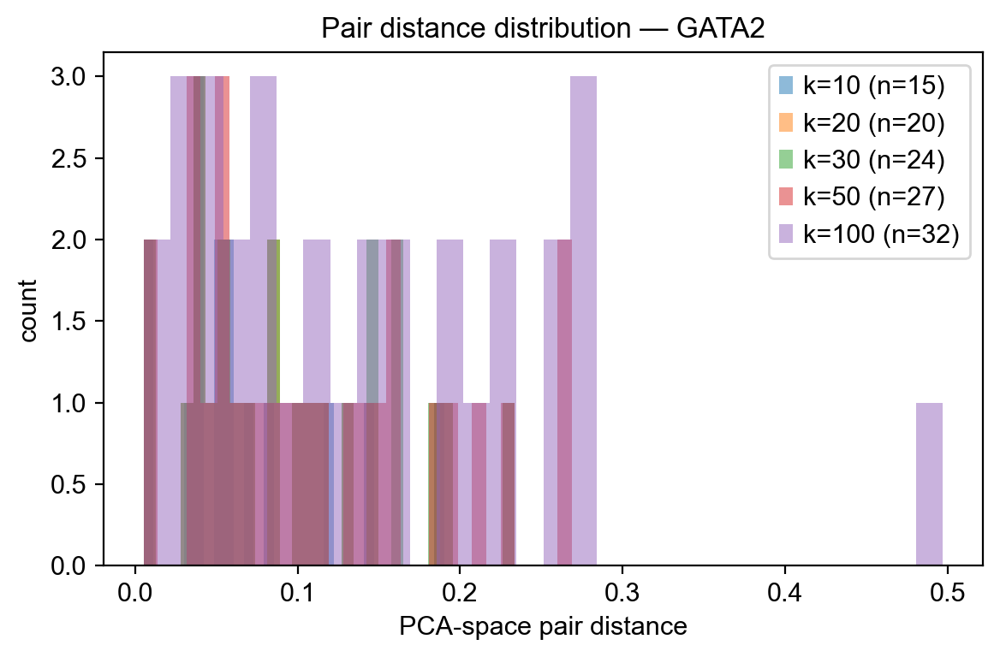

In [42]:
GENE = "GATA2"  # <-- set manually
K_VALUES = [10, 20, 30, 50, 100]
PCA_COLS = pca_cols[:2]  # same PC columns used to build velo_df

results = {}
for k in K_VALUES:
    pairs = pair_cells_mnn(GENE, z_scores, velo_df, mv_data, k=k, coord_cols=PCA_COLS)
    if pairs.empty:
        results[k] = np.array([])
        continue
    hi = velo_df.loc[pairs["partner_hi"], PCA_COLS].values
    lo = velo_df.loc[pairs["partner_lo"], PCA_COLS].values
    results[k] = np.linalg.norm(hi - lo, axis=1)

for k, dists in results.items():
    n = len(dists)
    med = np.median(dists) if n else float("nan")
    print(f"k={k:>3}: {n:>5} pairs  |  median dist = {med:.3f}")

fig, ax = plt.subplots(figsize=(6, 4))
for k, dists in results.items():
    if len(dists):
        ax.hist(dists, bins=30, alpha=0.5, label=f"k={k} (n={len(dists)})")
ax.set_xlabel("PCA-space pair distance")
ax.set_ylabel("count")
ax.set_title(f"Pair distance distribution — {GENE}")
ax.legend()
plt.tight_layout()
plt.show()

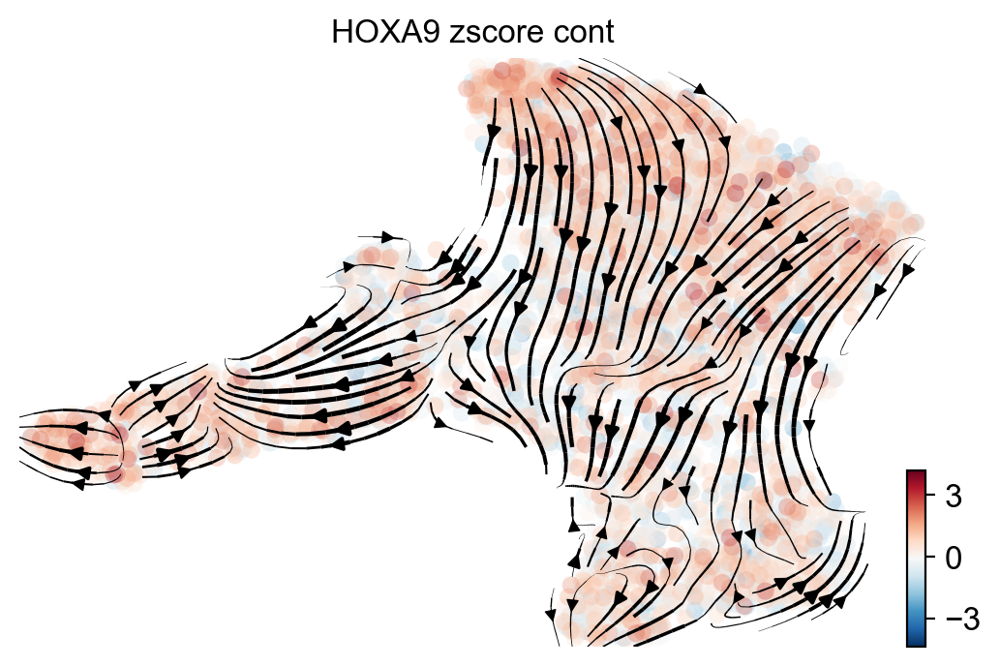

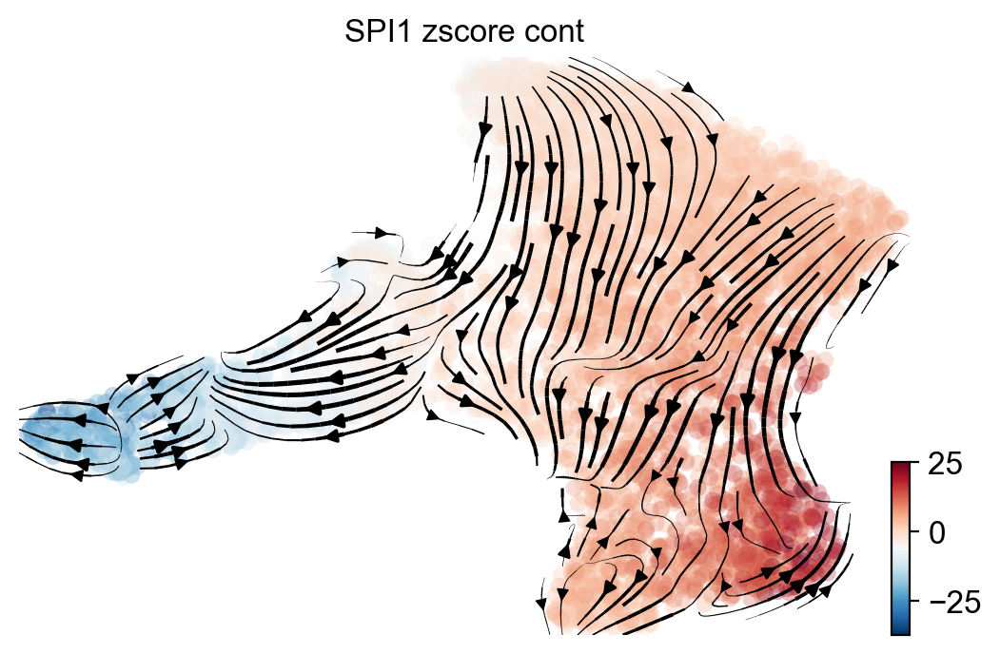

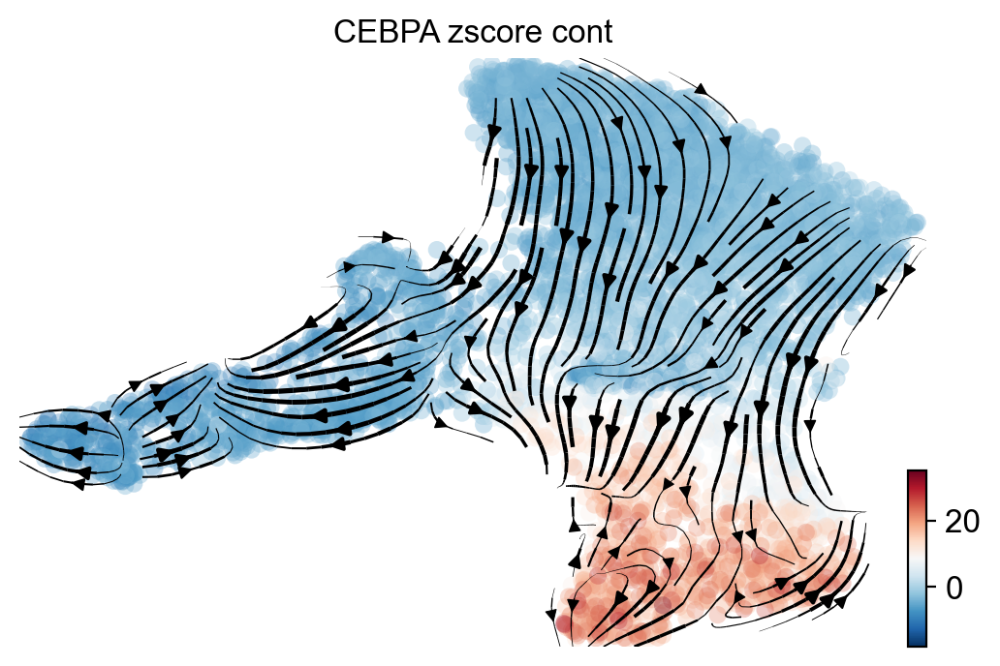

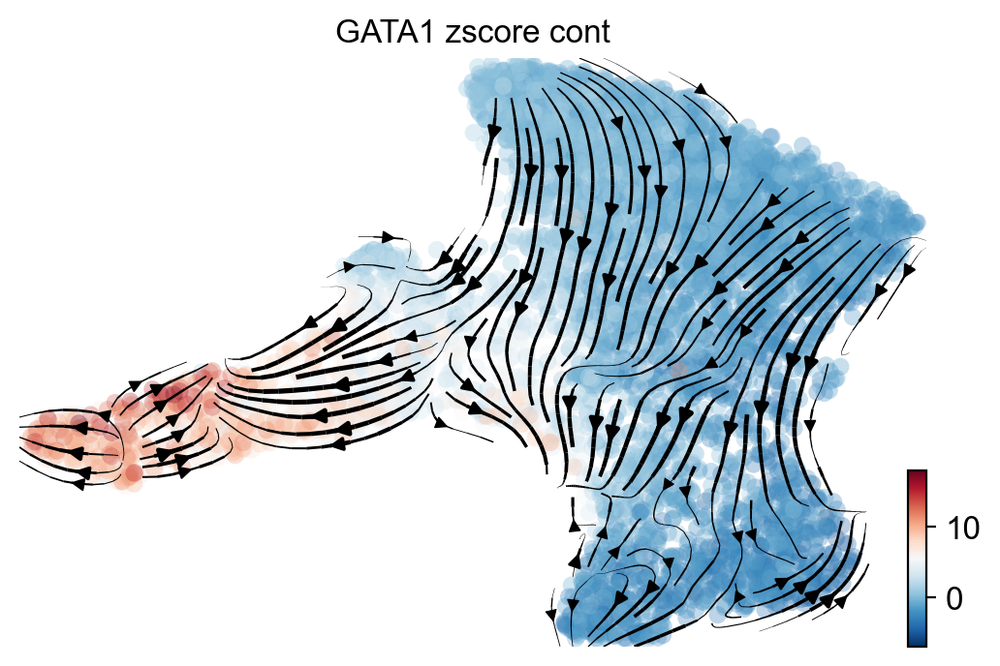

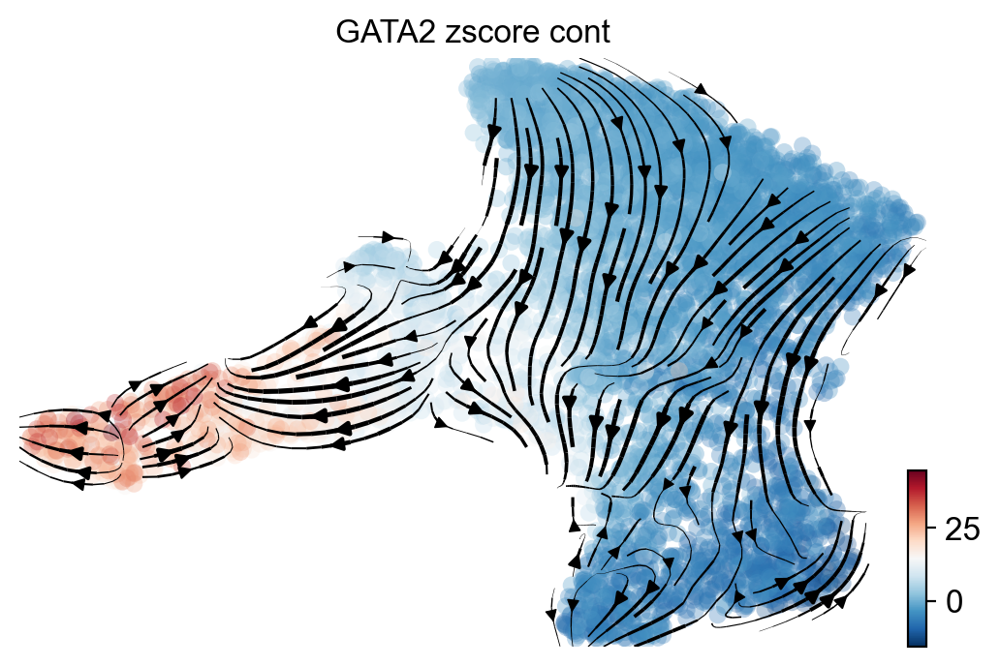

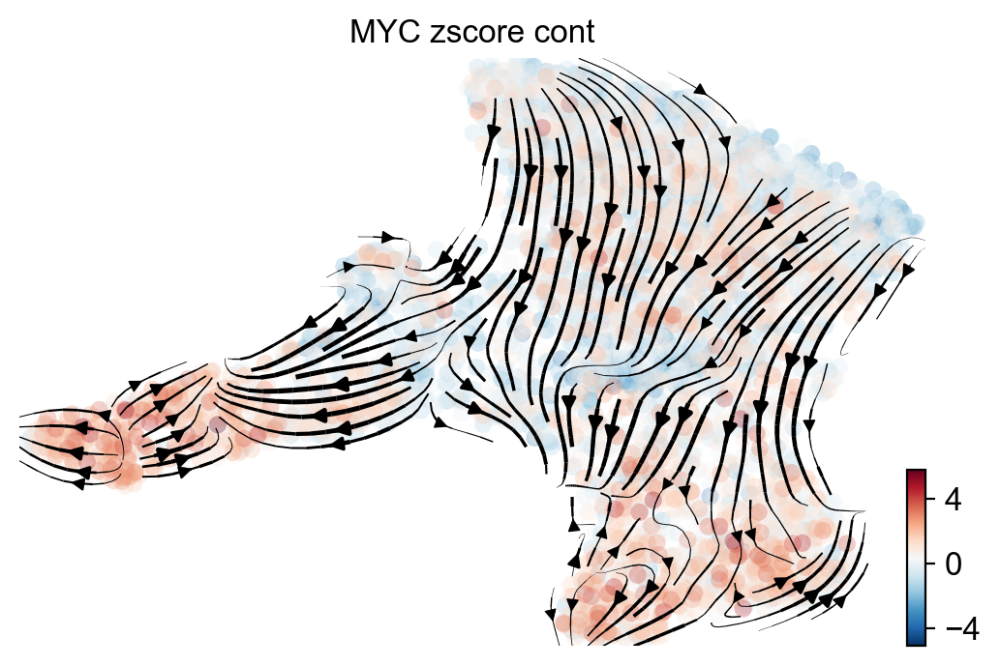

In [14]:
for i, tf in enumerate(tfs): 

    tf_data = z_scores[:, tf].X.flatten()
    tf_data = pd.Series(tf_data, index=z_scores.obs_names).reindex(mv_data.obs_names)

    mv_data.obs[f"{tf}_zscore_cont"] = pd.Series(tf_data, index=z_scores.obs_names).reindex(mv_data.obs_names)
    mv.velocity_embedding_stream(mv_data, basis='umap', color=f'{tf}_zscore_cont')

In [15]:
mv_data.obsm["abs_velo_s"] = np.linalg.norm(mv_data.layers["velo_s"], axis=-1)

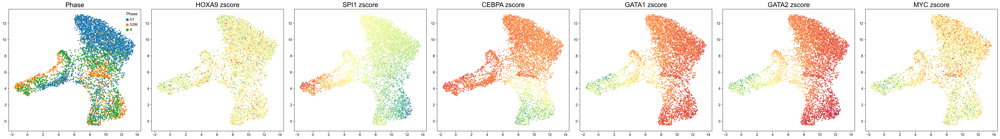

In [91]:
fig, axs = plt.subplots(nrows=1, ncols=len(tfs) + 1, figsize=((len(tfs) + 1) * 6, 6))

for i in range(len(tfs) + 1):
    if i == 0:
        phases = mv_data.obs["Phase"].cat.categories
        for phase in phases:
            mask = mv_data.obs["Phase"] == phase
            axs[i].scatter(
                mv_data.obsm["X_umap"][mask, 0],
                mv_data.obsm["X_umap"][mask, 1],
                s=6,
                label=str(phase),
            )

        axs[i].set_title("Phase", size=20)
        axs[i].legend(title="Phase", markerscale=3, frameon=True)
    else:
        tf = tfs[i - 1]
        accessibility = mv_data.obs[f"{tf}_zscore_cont"]

        axs[i].scatter(
            mv_data.obsm["X_umap"][:, 0],
            mv_data.obsm["X_umap"][:, 1],
            c=accessibility,
            s=6,
            cmap="Spectral",
        )
        axs[i].set_title(f"{tf} zscore", size=20)

plt.tight_layout()
plt.show()

## Compute Delta Velocities
First compute the difference for the curated set of TFs, then use an unbiased approach and do a sweep across all motifs in the chromVAR data

In [71]:
delta_data = {}

for tf in tfs:

    pairing_df = pair_cells_mnn(tf, z_scores, velo_df, mv_data, coord_cols=pca_cols[:2], k=10)

    v_diffs = []
    #rho_diffs = []
    z_diffs = []
    phases = []

    for _, row in pairing_df.iterrows():
        z_diff = z_scores[row["partner_hi"], tf].X.flatten() - z_scores[row["partner_lo"], tf].X.flatten()

        v_diff = vec_diff(vpca.loc[row["partner_hi"], :], vpca.loc[row["partner_lo"], :])

        phase_hi = mv_data.obs["Phase"][row["partner_hi"]]
        phase_lo = mv_data.obs["Phase"][row["partner_lo"]]
        phase_combo = (phase_hi, phase_lo)

        #v_diff = vec_diff(vpca.loc[row["partner_hi"], :], vpca.loc[row["partner_lo"], :])

        # v_diff = vec_diff(
        #     np.array([velo_df.loc[row["partner_hi"], "vx"], velo_df.loc[row["partner_hi"], "vy"]]),
        #     np.array([velo_df.loc[row["partner_lo"], "vx"], velo_df.loc[row["partner_lo"], "vy"]])
        # )

        # rho_diff = angle_between(
        #     np.array([velo_df.loc[row["partner_hi"], "vx"], velo_df.loc[row["partner_hi"], "vy"]]),
        #     np.array([velo_df.loc[row["partner_lo"], "vx"], velo_df.loc[row["partner_lo"], "vy"]])
        # )

        #rho_diffs.append(rho_diff)
        v_diffs.append(v_diff)
        z_diffs.append(z_diff)
        phases.append(phase_combo)

    z_diffs = np.concatenate(z_diffs)

    delta_data[tf] = {"z_diffs": z_diffs, "v_diffs": v_diffs, "phases": phases}#, "rho_diffs": rho_diffs}

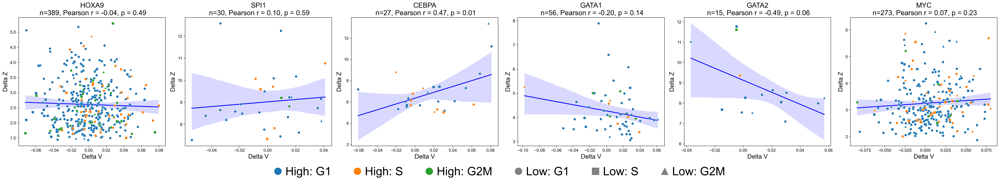

In [93]:
tfs_plot = list(tfs)

res = {tf: pearsonr(delta_data[tf]["v_diffs"], delta_data[tf]["z_diffs"])
       for tf in tfs_plot}
r_vals = np.array([res[tf][0] for tf in tfs_plot])
p_raw = np.array([res[tf][1] for tf in tfs_plot])

_, p_adj, _, _ = multipletests(p_raw, method="fdr_bh")
p_adj = dict(zip(tfs_plot, p_adj))

hi_colors = {"G1": "tab:blue", "S": "tab:orange", "G2M": "tab:green"}
lo_markers = {"G1": "o", "S": "s", "G2M": "^"}

tfs_plot = list(tfs)

res = {tf: pearsonr(delta_data[tf]["v_diffs"], delta_data[tf]["z_diffs"])
       for tf in tfs_plot}
r_vals = np.array([res[tf][0] for tf in tfs_plot])
p_raw = np.array([res[tf][1] for tf in tfs_plot])
p_adj = multipletests(p_raw, method="fdr_bh")[1]

fig, axs = plt.subplots(nrows=1, ncols=6, figsize=(6*6, 6))

for i, tf in enumerate(tfs_plot):
    data = delta_data[tf]
    x = np.asarray(data["v_diffs"])
    y = np.asarray(data["z_diffs"])
    phases = np.asarray(data["phases"])
    hi = np.array([p[0] for p in phases])
    lo = np.array([p[1] for p in phases])

    sns.regplot(x=x, y=y, ax=axs[i], ci=95, scatter=False,
                line_kws={"color": "blue", "linewidth": 2})

    for h, col in hi_colors.items():
        for l, mk in lo_markers.items():
            m = (hi == h) & (lo == l)
            if m.any():
                axs[i].scatter(x[m], y[m], c=col, marker=mk, s=40,
                               edgecolor="white", linewidth=0.4, zorder=3)

    axs[i].set_xlabel("Delta V", fontsize=16)
    axs[i].set_ylabel("Delta Z", fontsize=16)
    axs[i].set_title(f"{tf}\n n={len(x)}, Pearson r = {r_vals[i]:.2f}, p = {p_raw[i]:.2f}", fontsize=18)

# two-part legend: color = high cell phase, shape = low cell phase
handles = (
    [Line2D([], [], marker="o", ls="", color=c, markersize=18, label=f"High: {h}") for h, c in hi_colors.items()]
    + [Line2D([], [], marker=m, ls="", color="gray", markersize=18, label=f"Low: {l}") for l, m in lo_markers.items()]
)
#axs[0].legend(handles=handles, fontsize=11, ncol=2)
fig.legend(handles=handles, loc="lower center", ncol=6, fontsize=30,
           frameon=False, bbox_to_anchor=(0.5, -0.14))

plt.tight_layout()
plt.show()

## Per gene analysis
Test which gene's single velocity is affected most by differences in motif accessibility of select TFs.

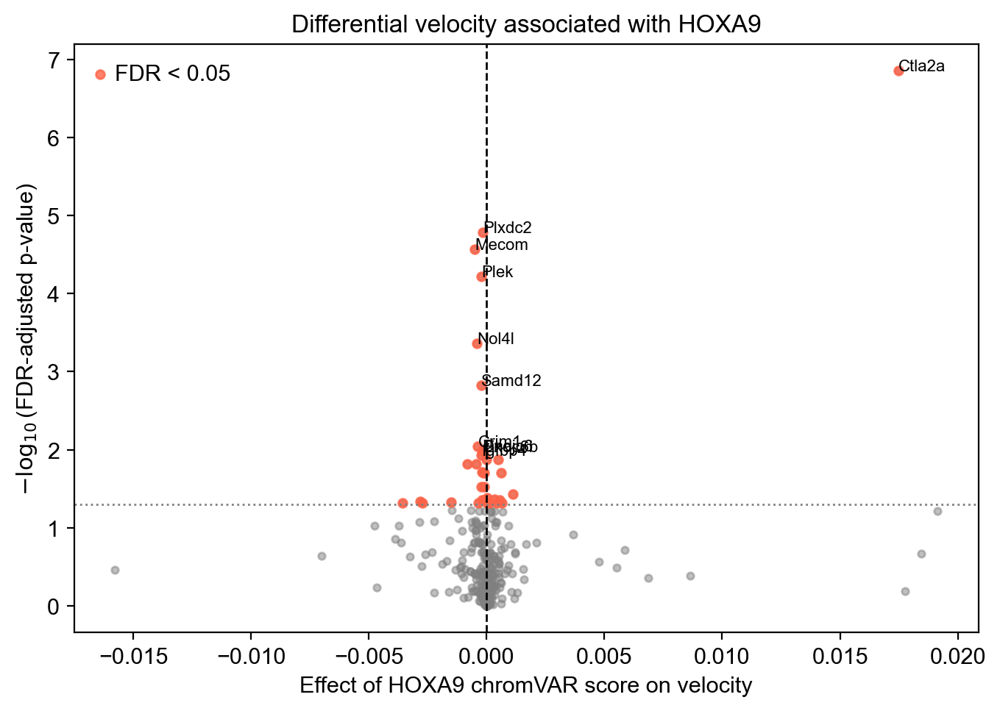

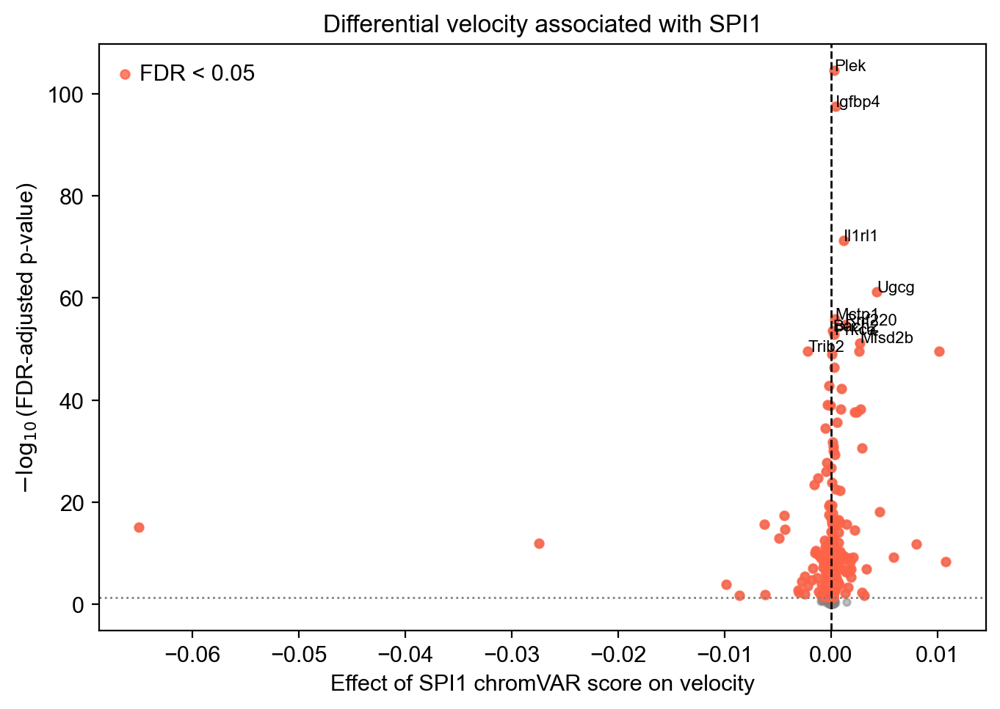

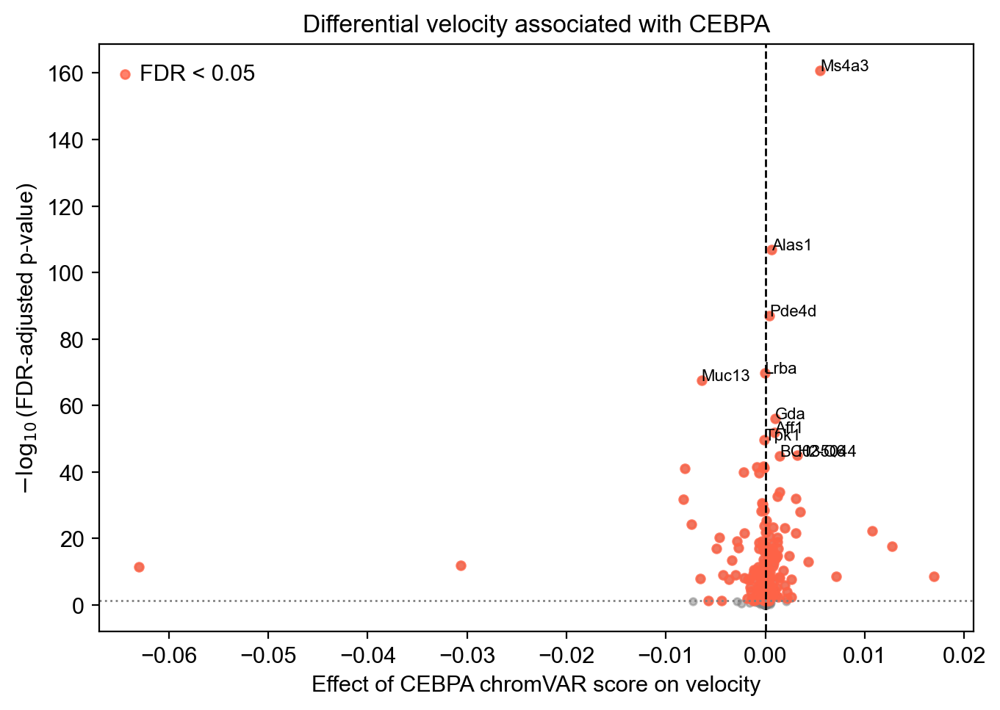

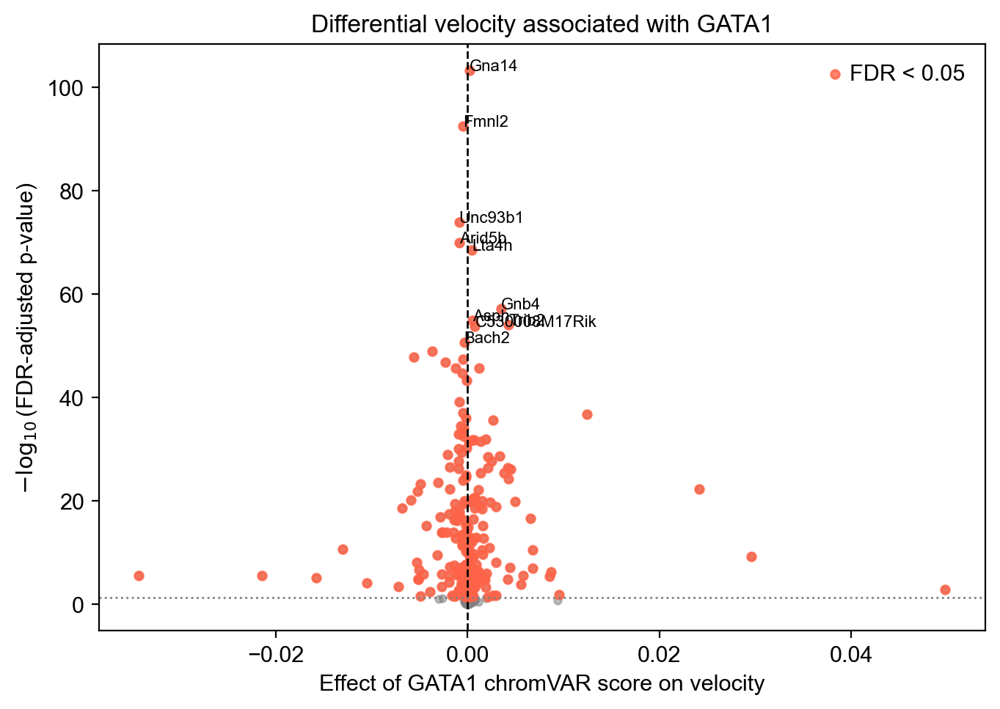

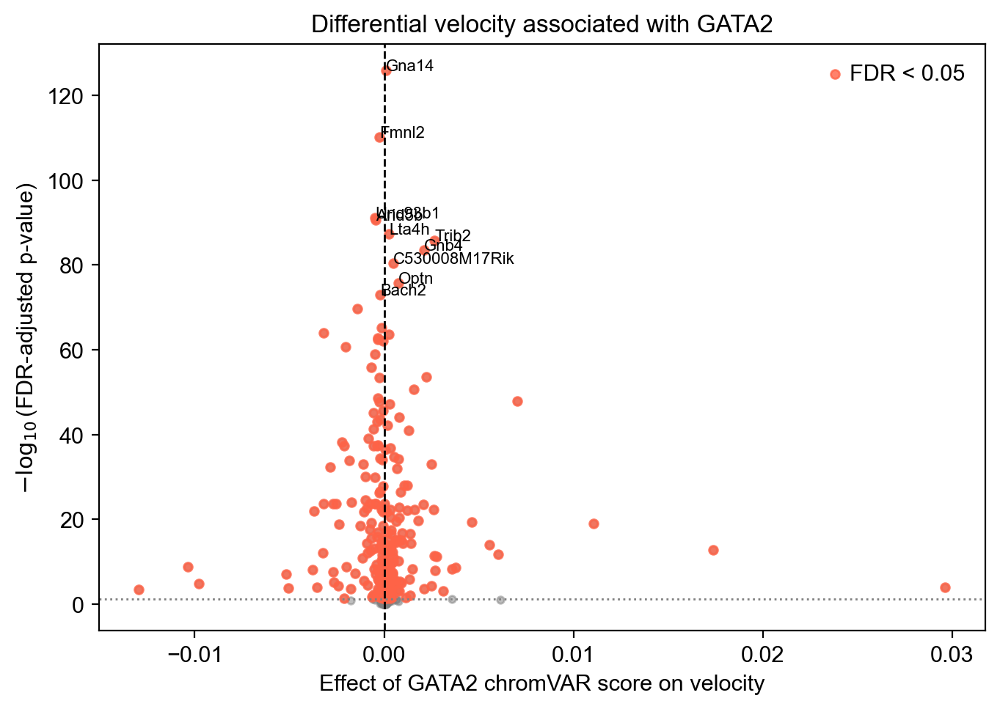

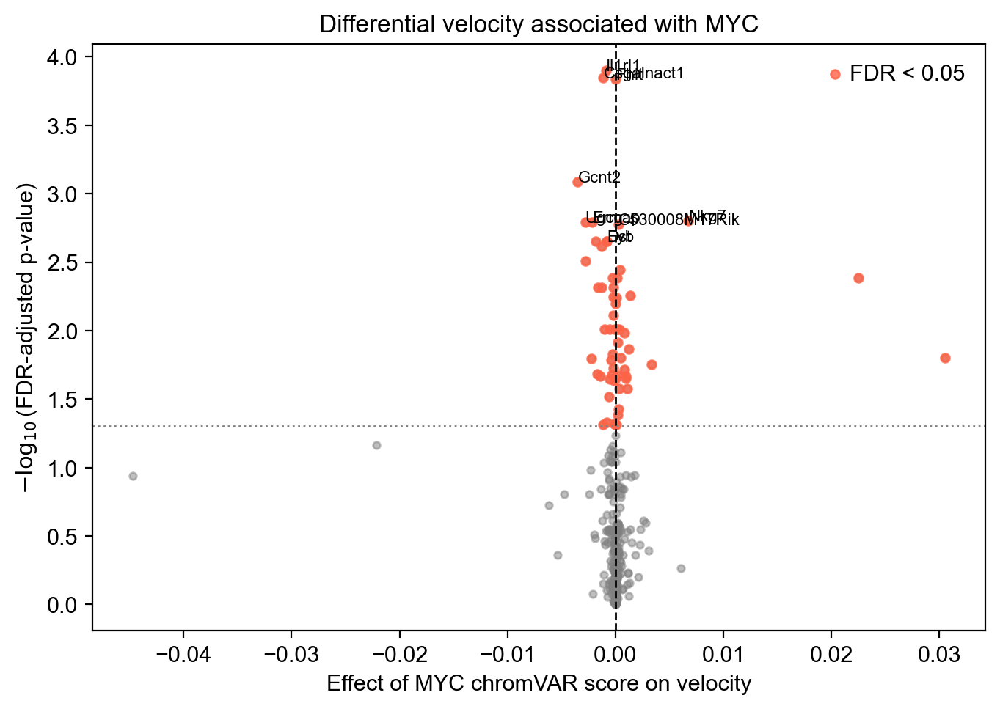

In [32]:
velocity = pd.DataFrame(
    mv_data.layers["velo_s"],
    index=mv_data.obs_names,
    columns=mv_data.var_names,
)

chromvar = pd.DataFrame(
    z_scores.X,
    index=mv_data.obs_names,
    columns=z_scores.var_names,
)

rna_pcs = pd.DataFrame(
    mv_data.obsm["X_pca"][:, :10],
    index=mv_data.obs_names,
    columns=[f"PC{i+1}" for i in range(10)],
)

for motif in tfs:

    # Align all matrices to the same cells
    cells = (
        velocity.index
        .intersection(chromvar.index)
        .intersection(rna_pcs.index)
    )

    V = velocity.loc[cells]
    z = chromvar.loc[cells, motif]
    P = rna_pcs.loc[cells]

    # Regression predictors: motif score + RNA PCs -> model velocity using motif score and RNA location
    X = pd.concat([z.rename("motif_score"), P], axis=1)
    X = sm.add_constant(X)

    results = []

    for gene in V.columns:
        # Remove missing values for this gene
        valid = V[gene].notna() & X.notna().all(axis=1)

        y = V.loc[valid, gene]
        x = X.loc[valid]

        # Fit linear regression
        fit = sm.OLS(y, x).fit()

        results.append({
            "gene": gene,
            "beta": fit.params["motif_score"],
            "pvalue": fit.pvalues["motif_score"],
        })

    results = pd.DataFrame(results)

    # Correct for testing many genes
    results["padj"] = multipletests(
        results["pvalue"],
        method="fdr_bh"
    )[1]

    # Avoid log10(0)
    results["neglog10_padj"] = -np.log10(
        results["padj"].clip(lower=1e-300)
    )

    fig, ax = plt.subplots(figsize=(7, 5))

    # All genes
    ax.scatter(
        results["beta"],
        results["neglog10_padj"],
        s=12,
        alpha=0.5,
        color="gray",
    )

    # Highlight genes passing FDR < 0.05
    sig = results["padj"] < 0.05

    ax.scatter(
        results.loc[sig, "beta"],
        results.loc[sig, "neglog10_padj"],
        s=18,
        alpha=0.8,
        color="tomato",
        label="FDR < 0.05",
    )

    top_genes = results.nsmallest(10, "padj")

    for _, row in top_genes.iterrows():
        ax.annotate(
            row["gene"],
            (row["beta"], row["neglog10_padj"]),
            fontsize=8,
        )

    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.axhline(-np.log10(0.05), color="gray", linestyle=":", linewidth=1)

    ax.set_xlabel(f"Effect of {motif} chromVAR score on velocity")
    ax.set_ylabel(r"$-\log_{10}$(FDR-adjusted p-value)")
    ax.set_title(f"Differential velocity associated with {motif}")
    ax.legend(frameon=False)

    plt.tight_layout()
    plt.show()

## Perform a sweep across all available motifs

In [ ]:
all_tfs = z_scores.var_names.values

sweep_delta_data = {}
#corrs_rho = {}
corrs_v = {}

for i, tf in enumerate(all_tfs):

    pairing_df = pair_cells_mnn(tf, z_scores, velo_df, mv_data, coord_cols=pca_cols[:2], k=10)

    v_diffs = []
    #rho_diffs = []
    z_diffs = []
    phases = []

    for _, row in pairing_df.iterrows():
        z_diff = z_scores[row["partner_hi"], tf].X.flatten() - z_scores[row["partner_lo"], tf].X.flatten()
        
        v_diff = vec_diff(vpca.loc[row["partner_hi"], :], vpca.loc[row["partner_lo"], :])
        
        phase_hi = mv_data.obs["Phase"][row["partner_hi"]]
        phase_lo = mv_data.obs["Phase"][row["partner_lo"]]
        phase_combo = (phase_hi, phase_lo)

        # v_diff = vec_diff(
        #     np.array([velo_df.loc[row["partner_hi"], "vx"], velo_df.loc[row["partner_hi"], "vy"]]),
        #     np.array([velo_df.loc[row["partner_lo"], "vx"], velo_df.loc[row["partner_lo"], "vy"]])
        # )

        # rho_diff = angle_between(
        #     np.array([velo_df.loc[row["partner_hi"], "vx"], velo_df.loc[row["partner_hi"], "vy"]]),
        #     np.array([velo_df.loc[row["partner_lo"], "vx"], velo_df.loc[row["partner_lo"], "vy"]])
        # )

        #rho_diffs.append(np.abs(rho_diff))
        v_diffs.append(np.abs(v_diff))
        z_diffs.append(z_diff)
        phases.append(phase_combo)

    z_diffs = np.concatenate(z_diffs)

    sweep_delta_data[tf] = {"z_diffs": z_diffs, "v_diffs": v_diffs, "phases": phases}#, "rho_diffs": rho_diffs}

    r_vz, p_vz = pearsonr(v_diffs, z_diffs)
    #r_rhoz, p_rhoz = pearsonr(rho_diffs, z_diffs)
    #corrs_rho[tf] = r_rhoz
    corrs_v[tf] = r_vz
    if i==0: 
        print("Completed first iteration.")
    if (i+1)%100==0:
        print(f"Completed analysis of [{i+1}/{len(all_tfs)}]")

Completed analysis of [25/746]
Completed analysis of [50/746]
Completed analysis of [75/746]
Completed analysis of [100/746]
Completed analysis of [125/746]
Completed analysis of [150/746]
Completed analysis of [175/746]
Completed analysis of [200/746]
Completed analysis of [225/746]
Completed analysis of [250/746]
Completed analysis of [275/746]
Completed analysis of [300/746]
Completed analysis of [325/746]
Completed analysis of [350/746]
Completed analysis of [375/746]
Completed analysis of [400/746]
Completed analysis of [425/746]
Completed analysis of [450/746]
Completed analysis of [475/746]
Completed analysis of [500/746]
Completed analysis of [525/746]
Completed analysis of [550/746]
Completed analysis of [575/746]
Completed analysis of [600/746]
Completed analysis of [625/746]
Completed analysis of [650/746]
Completed analysis of [675/746]
Completed analysis of [700/746]
Completed analysis of [725/746]


In [80]:
#sorted_corrs_rho = {k: v for k, v in sorted(corrs_rho.items(), key=lambda item: item[1], reverse=True)}
sorted_corrs_v = {k: v for k, v in sorted(corrs_v.items(), key=lambda item: item[1], reverse=True)}
unbiased_tfs = sorted_corrs_v.keys()

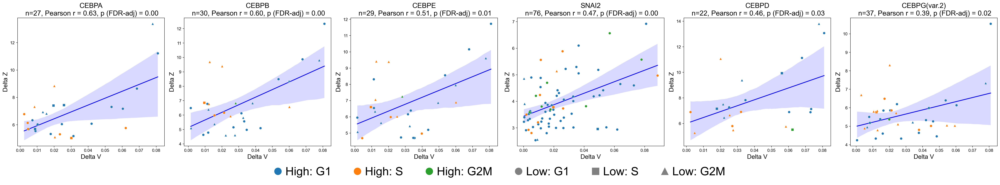

In [92]:
tfs_plot = list(unbiased_tfs)[:6]

res = {tf: pearsonr(sweep_delta_data[tf]["v_diffs"], sweep_delta_data[tf]["z_diffs"])
       for tf in tfs_plot}
r_vals = np.array([res[tf][0] for tf in tfs_plot])
p_raw = np.array([res[tf][1] for tf in tfs_plot])

_, p_adj, _, _ = multipletests(p_raw, method="fdr_bh")
p_adj = dict(zip(tfs_plot, p_adj))

hi_colors = {"G1": "tab:blue", "S": "tab:orange", "G2M": "tab:green"}
lo_markers = {"G1": "o", "S": "s", "G2M": "^"}

res = {tf: pearsonr(sweep_delta_data[tf]["v_diffs"], sweep_delta_data[tf]["z_diffs"])
       for tf in tfs_plot}
r_vals = np.array([res[tf][0] for tf in tfs_plot])
p_raw = np.array([res[tf][1] for tf in tfs_plot])
p_adj = multipletests(p_raw, method="fdr_bh")[1]

fig, axs = plt.subplots(nrows=1, ncols=6, figsize=(6*6, 6))

for i, tf in enumerate(tfs_plot):
    data = sweep_delta_data[tf]
    x = np.asarray(data["v_diffs"])
    y = np.asarray(data["z_diffs"])
    phases = np.asarray(data["phases"])
    hi = np.array([p[0] for p in phases])
    lo = np.array([p[1] for p in phases])

    sns.regplot(x=x, y=y, ax=axs[i], ci=95, scatter=False,
                line_kws={"color": "blue", "linewidth": 2})

    for h, col in hi_colors.items():
        for l, mk in lo_markers.items():
            m = (hi == h) & (lo == l)
            if m.any():
                axs[i].scatter(x[m], y[m], c=col, marker=mk, s=40,
                               edgecolor="white", linewidth=0.4, zorder=3)

    axs[i].set_xlabel("Delta V", fontsize=16)
    axs[i].set_ylabel("Delta Z", fontsize=16)
    axs[i].set_title(f"{tf}\n n={len(x)}, Pearson r = {r_vals[i]:.2f}, p (FDR-adj) = {p_adj[i]:.2f}", fontsize=18)

# two-part legend: color = high cell phase, shape = low cell phase
handles = (
    [Line2D([], [], marker="o", ls="", color=c, markersize=18, label=f"High: {h}") for h, c in hi_colors.items()]
    + [Line2D([], [], marker=m, ls="", color="gray", markersize=18, label=f"Low: {l}") for l, m in lo_markers.items()]
)
#axs[0].legend(handles=handles, fontsize=11, ncol=2)
fig.legend(handles=handles, loc="lower center", ncol=6, fontsize=30,
           frameon=False, bbox_to_anchor=(0.5, -0.14))

plt.tight_layout()
plt.show()